# CPE15 Activity 11
## GIS and GeoPandas Fundamentals

**Scenario:** Public-Service Accessibility Mapping  
**Course:** Professional Elective 1: Programming for Data Science  
**Week:** 13  
**Mode:** Individual, in class or take home  
**Suggested completion time:** 5 to 6 hours  
**Total:** 100 points

### Student Information

**Name:** WRITE YOUR FULL NAME  
**Student number:** WRITE YOUR STUDENT NUMBER  
**Section:** WRITE YOUR SECTION  
**Date performed:** YYYY-MM-DD  
**Date submitted:** YYYY-MM-DD

> Rename this file as `Surname_Firstname_CPE15_Activity11.ipynb` before submission.

## Activity Purpose

Represent synthetic public-service facilities as spatial and attribute data, compare point, line, and polygon roles, manage coordinate reference systems, measure in projected units, round-trip GeoJSON, and apply privacy-aware generalization.

## Learning Outcomes

1. Construct a GeoDataFrame from attributes and point geometry.
2. Explain point, line, and polygon representations.
3. Assign and transform a CRS before distance or area measurement.
4. Export, import, and reconcile GeoJSON.
5. Communicate spatial privacy, source authority, and measurement limitations.

## General Instructions

1. Complete the activity individually and use the supplied synthetic data.
2. Do not delete or rewrite a cell labeled **STARTER DATA**.
3. Write the requested prediction before executing each part.
4. Complete every **STUDENT CODE** cell and keep the output visible.
5. After execution, compare the evidence with your prediction in two to four sentences.
6. Label quantities with units, denominators, and scope.
7. Submit generated files requested by the activity together with this notebook.
8. Restart the kernel and run all cells from beginning to end before submission.

No separate laboratory report is required.

## Required CSV Files

Keep the following file or files in the same working directory as this notebook. Do not rename them.

1. `CPE15_Activity11_Accessible_Facilities.csv`

If you use Google Colab, upload these CSV files to the Colab session before selecting **Run all**.


## Part 1: Spatial and Attribute Data (10 points)

**Context:** Five fictional public-service facilities have a name, service type, daily capacity, longitude, and latitude.

### Required Tasks

1. Create a pandas DataFrame.
2. Convert coordinates to point geometry.
3. Create a GeoDataFrame in EPSG:4326.
4. Report geometry type, CRS, row count, and attribute fields.
5. Define one row precisely.

**Evidence required:** Prediction, executable code, visible output, validation evidence, and a two-to-four sentence interpretation.

### Part 1 Prediction

Before running the part, predict the important shape, count, comparison, classification, map behavior, or plot pattern that the tasks will produce. Explain the reason for your prediction.

**Prediction:** WRITE YOUR PREDICTION HERE.

In [1]:
# STARTER DATA: Do not manually alter these values.
from pathlib import Path
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point, LineString, Polygon

DATA_FILE = Path('CPE15_Activity11_Accessible_Facilities.csv')
facilities_df = pd.read_csv(DATA_FILE)
print(f'Loaded {len(facilities_df)} facilities from {DATA_FILE.name}')

Loaded 20 facilities from CPE15_Activity11_Accessible_Facilities.csv


In [2]:
# STUDENT CODE: Build and inspect the GeoDataFrame.

# Make one Point for each longitude and latitude pair.
geometry = [Point(lon, lat) for lon, lat in zip(facilities_df['longitude'], facilities_df['latitude'])]

# Turn the pandas DataFrame into a GeoDataFrame.
facilities = gpd.GeoDataFrame(facilities_df, geometry=geometry, crs='EPSG:4326')

# Validation checks.
print('Geometry type:', facilities.geometry.geom_type.unique())
print('CRS:', facilities.crs)
print('Row count:', len(facilities))
print('Attribute fields:', list(facilities.columns))
print('Unique facility IDs:', facilities['facility_id'].nunique())
print('All geometries nonempty:', facilities.geometry.notna().all() and not facilities.geometry.is_empty.any())
print('Longitude range:', facilities['longitude'].min(), 'to', facilities['longitude'].max())
print('Latitude range:', facilities['latitude'].min(), 'to', facilities['latitude'].max())

print()
print('One row defined precisely:')
row = facilities.iloc[0]
print('facility_id:', row['facility_id'])
print('name:', row['name'])
print('service:', row['service'])
print('daily_capacity:', row['daily_capacity'], 'persons per day')
print('longitude:', row['longitude'], 'degrees east')
print('latitude:', row['latitude'], 'degrees north')
print('geometry:', row['geometry'])

Geometry type: <StringArray>
['Point']
Length: 1, dtype: str
CRS: EPSG:4326
Row count: 20
Attribute fields: ['facility_id', 'name', 'service', 'daily_capacity', 'longitude', 'latitude', 'geometry']
Unique facility IDs: 20
All geometries nonempty: True
Longitude range: 121.617 to 121.6264
Latitude range: 13.9345 to 13.94105

One row defined precisely:
facility_id: F01
name: Administrative Service Point 1
service: Administrative
daily_capacity: 45 persons per day
longitude: 121.617 degrees east
latitude: 13.9345 degrees north
geometry: POINT (121.617 13.9345)


In [3]:
# STUDENT CODE: Build and inspect the GeoDataFrame.
geometry = [ Point(lon, lat)
     for lon, lat in
         zip(
             facilities_df['longitude'],
             facilities_df['latitude']
         )
]

facilities = gpd.GeoDataFrame(
    facilities_df,
    geometry=geometry,
    crs='EPSG:4326'
)

print('Geometry type: ', facilities.geometry.geom_type.unique())
print('CRS: ', facilities.crs)
print('Row Count: ', len(facilities))
print('Attributes field: ', list(facilities.columns))
print('Unique facilities IDs: ', facilities['facility_id'].nunique())
print('All geometrics nonempty: ',
      facilities.geometry.notna().all() and
      not facilities.geometry.is_empty.any()
     )
print('Longitude range: ',
      facilities['longitude'].min(),
      'to',
      facilities['longitude'].max())
print('Latitude range: ',
      facilities['latitude'].min(),
      'to',
      facilities['latitude'].max()
     )
# Add validation and labeled output required by the instructions.

Geometry type:  <StringArray>
['Point']
Length: 1, dtype: str
CRS:  EPSG:4326
Row Count:  20
Attributes field:  ['facility_id', 'name', 'service', 'daily_capacity', 'longitude', 'latitude', 'geometry']
Unique facilities IDs:  20
All geometrics nonempty:  True
Longitude range:  121.617 to 121.6264
Latitude range:  13.9345 to 13.94105


### Part 1 Evidence and Explanation

Compare the actual result with your prediction. Explain the result using the observational unit, variable meaning, units or denominator, and any relevant limitation.

**Response:** WRITE TWO TO FOUR SENTENCES HERE.

## Part 2: Points, Lines, and Polygons (10 points)

**Context:** The map needs facility locations, one illustrative walking route, and one planning extent.

### Required Tasks

1. Create a line through three ordered facility points.
2. Create a polygon enclosing the activity area.
3. Store each geometry in a GeoDataFrame with the same CRS.
4. Plot all geometry types together.
5. Explain what each geometry abstracts.

**Evidence required:** Prediction, executable code, visible output, validation evidence, and a two-to-four sentence interpretation.

### Part 2 Prediction

Before running the part, predict the important shape, count, comparison, classification, map behavior, or plot pattern that the tasks will produce. Explain the reason for your prediction.

**Prediction:** WRITE YOUR PREDICTION HERE.

In [4]:
# STARTER DATA: Do not manually alter these values.
route=LineString([
    facilities.geometry.iloc[0],
    facilities.geometry.iloc[2],
    facilities.geometry.iloc[4]
])

extent=Polygon([
    (121.616,13.934),
    (121.627,13.934),
    (121.627,13.942),
    (121.616,13.942)
])

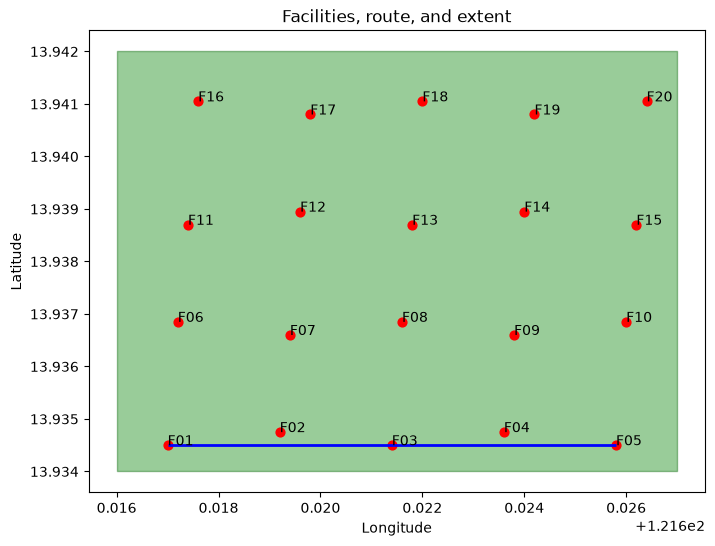

In [19]:
# STUDENT CODE: Build, plot, and interpret the three geometry roles.

route_gdf = gpd.GeoDataFrame(
    {'feature': ['Illustrative walking route']},
    geometry=[route],
    crs='EPSG:4326'
)

extent_gdf = gpd.GeoDataFrame(
    {'feature': ['Planning extent']},
    geometry=[extent],
    crs='EPSG:4326'
)

fig, ax = plt.subplots(figsize=(8,6))

extent_gdf.plot(ax=ax,
                facecolor='green',
                edgecolor='darkgreen',
                alpha=0.4
)

route_gdf.plot(ax=ax,
              color='blue',
              linewidth=2
)

facilities.plot(ax=ax, color='red', markersize=40)

for i, row in facilities.iterrows():
    x = row.geometry.x
    y = row.geometry.y
    ax.annotate(row['facility_id'], (x, y), fontsize=10)

ax.set_title('Facilities, route, and extent')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.show()
# Add validation and labeled output required by the instructions.

### Part 2 Evidence and Explanation

Compare the actual result with your prediction. Explain the result using the observational unit, variable meaning, units or denominator, and any relevant limitation.

**Response:** WRITE TWO TO FOUR SENTENCES HERE.

## Part 3: CRS Transformation, Distance, and Area (10 points)

**Context:** Angular longitude and latitude coordinates must be projected before reporting metres or square metres.

### Required Tasks

1. Transform all layers to EPSG:32651.
2. Calculate distance from each facility to F01 in metres.
3. Calculate polygon area in hectares.
4. Verify projected CRS equality and units.
5. State projection limitations.

**Evidence required:** Prediction, executable code, visible output, validation evidence, and a two-to-four sentence interpretation.

### Part 3 Prediction

Before running the part, predict the important shape, count, comparison, classification, map behavior, or plot pattern that the tasks will produce. Explain the reason for your prediction.

**Prediction:** WRITE YOUR PREDICTION HERE.

In [6]:
# STARTER DATA: Do not manually alter these values.
projected_crs='EPSG:32651'

In [30]:
# STUDENT CODE: Project before measuring and label every unit.
facilities_proj = facilities.to_crs(projected_crs)
route_proj = route_gdf.to_crs(projected_crs)
extent_proj = extent_gdf.to_crs(projected_crs)

f01 = facilities_proj[
    facilities_proj['facility_id'] == 'F01'
].geometry.iloc[0]

facilities['distance_to_F01_m'] = facilities_proj.geometry.distance(f01)

distances_str = facilities_proj[
    ['facility_id', 'distance_to_F01_m']
].to_string(index=False)

print(distances_str)
# Add validation and labeled output required by the instructions.

facility_id  distance_to_F01_m
        F01           0.000000
        F02         239.315662
        F03         475.424568
        F04         713.672224
        F05         950.848304
        F06         260.865374
        F07         348.161810
        F08         560.914144
        F09         770.595092
        F10        1006.602893
        F11         466.630864
        F12         566.800094
        F13         696.321566
        F14         902.443881
        F15        1097.283076
        F16         727.488182
        F17         759.770544
        F18         903.826646
        F19        1044.479268
        F20        1247.641191


### Part 3 Evidence and Explanation

Compare the actual result with your prediction. Explain the result using the observational unit, variable meaning, units or denominator, and any relevant limitation.

**Response:** WRITE TWO TO FOUR SENTENCES HERE.

## Part 4: GeoJSON Round Trip (10 points)

**Context:** The point layer will be exchanged as a small web-oriented vector file.

### Required Tasks

1. Export the facilities to GeoJSON in EPSG:4326.
2. Read the file back.
3. Verify row count, IDs, CRS, geometry type, and nonempty geometry.
4. Report file size.
5. Explain what round-trip validation cannot prove.

**Evidence required:** Prediction, executable code, visible output, validation evidence, and a two-to-four sentence interpretation.

### Part 4 Prediction

Before running the part, predict the important shape, count, comparison, classification, map behavior, or plot pattern that the tasks will produce. Explain the reason for your prediction.

**Prediction:** WRITE YOUR PREDICTION HERE.

In [8]:
# STARTER DATA: Do not manually alter these values.
from pathlib import Path
geojson_path=Path('activity11_accessible_facilities.geojson')

In [9]:
# STUDENT CODE: Export, import, and reconcile the layer.

# Add validation and labeled output required by the instructions.

### Part 4 Evidence and Explanation

Compare the actual result with your prediction. Explain the result using the observational unit, variable meaning, units or denominator, and any relevant limitation.

**Response:** WRITE TWO TO FOUR SENTENCES HERE.

## Part 5: Privacy-Aware Generalization and Metadata (15 points)

**Context:** A public preview needs less positional precision than the internal synthetic source.

### Required Tasks

1. Create a public copy in EPSG:4326.
2. Round longitude and latitude to three decimal places and rebuild points.
3. Measure displacement in metres.
4. Retain the internal layer separately.
5. Write a source, purpose, CRS, privacy, and limitation note.

**Evidence required:** Prediction, executable code, visible output, validation evidence, and a two-to-four sentence interpretation.

### Part 5 Prediction

Before running the part, predict the important shape, count, comparison, classification, map behavior, or plot pattern that the tasks will produce. Explain the reason for your prediction.

**Prediction:** WRITE YOUR PREDICTION HERE.

In [10]:
# STARTER DATA: Do not manually alter these values.
public_preview=facilities.copy()

In [11]:
# STUDENT CODE: Generalize coordinates and quantify displacement.

# Add validation and labeled output required by the instructions.

### Part 5 Evidence and Explanation

Compare the actual result with your prediction. Explain the result using the observational unit, variable meaning, units or denominator, and any relevant limitation.

**Response:** WRITE TWO TO FOUR SENTENCES HERE.

## Guide Questions

1. **Why is geometry not a substitute for attributes?**

   Response: WRITE YOUR ANSWER HERE.

2. **Why transform rather than merely assign a projected CRS?**

   Response: WRITE YOUR ANSWER HERE.

3. **Why can generalized coordinates still be sensitive?**

   Response: WRITE YOUR ANSWER HERE.

## Science Communication Brief

Write a 140 to 180 word map metadata and accessibility note that defines one row, names both CRSs and measurement units, distinguishes illustrative routes from authoritative paths, explains coordinate generalization, and states at least two limitations.

**Brief:** WRITE YOUR FINAL BRIEF HERE.

## Reflection

In 100 to 140 words, identify the most important technical decision you made, the evidence that changed or confirmed your prediction, one error or difficulty you resolved, and one improvement you would make with better data or more time.

**Reflection:** WRITE YOUR RESPONSE HERE.

## AI-Use Disclosure

Select one statement and complete it.

**No AI used:** I completed this activity without generative AI assistance.

**AI used:** I used [TOOL] for [SPECIFIC PURPOSE]. It influenced [CELLS OR SECTIONS]. I verified the result by [METHOD] and changed [WHAT YOU CHANGED]. I can explain and defend every submitted result.

**Disclosure:** WRITE YOUR DISCLOSURE HERE.

## Assessment Rubric

| Criterion | Points |
|:--|--:|
| Part 1: Spatial and Attribute Data | 10 |
| Part 2: Points, Lines, and Polygons | 10 |
| Part 3: CRS Transformation, Distance, and Area | 10 |
| Part 4: GeoJSON Round Trip | 10 |
| Part 5: Privacy-Aware Generalization and Metadata | 15 |
| Data validation, reconciliation, and responsible handling | 10 |
| Accuracy and completeness of outputs | 10 |
| Interpretation, guide questions, and reflection | 10 |
| Science communication brief | 8 |
| Code readability and notebook organization | 4 |
| AI disclosure and submission compliance | 3 |
| **Total** | **100** |

## Final Submission Check

1. Rename the notebook `Surname_Firstname_CPE15_Activity11.ipynb`.
2. Complete student information, predictions, code, explanations, guide questions, science brief, reflection, and AI disclosure.
3. Confirm every required generated file exists and opens.
4. Restart the kernel and run all cells.
5. Confirm that no error traceback remains and all outputs are visible.
6. Submit the notebook and requested generated files. No separate laboratory report is required.